# 4.2 — Computational cost

Run all cells to download the saved timing measurements from the public B2
dataset and redraw the thesis figure. The saved figure can also be read
without execution.
No account, secret, GC2D installation,
JAX installation or trajectory integration is needed. NumPy and Matplotlib
are the only third-party packages used; both are available in Google Colab.

The measurements describe eight fixed-step methods on the **recorded JAX CPU
worker**, not the current Colab runtime: 40 particles, 500 cycles, 40 steps per
cycle and normalized gyro-radius 0.015. The first invocation includes
compilation. Three later invocations reuse the compiled integrator.
The numerical timing includes preparation, integration, synchronization and
host result construction; it excludes files, network transfers and plots.

Circles show the cached median and the minimum–maximum range of three
repetitions; diamonds show the first invocation. The upper axis divides the
same times by the fastest cached median (RK2), using one fixed denominator.
The ranges are not confidence intervals. These measurements do not establish
accuracy or a general ranking of the methods. All figure labels are French.

The notebook verifies the public manifest against a pinned SHA-256 digest,
then verifies both JSON files and the recorded timing protocol. It does not
download trajectories or repeat the original trajectory-completeness and
determinism audits. Their recorded result is reported as provenance.


In [1]:
from hashlib import sha256
import json
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.parse import urlsplit
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter
import numpy as np

PUBLIC_DATA_BASE_URL = "https://f003.backblazeb2.com/file/gc2d-colab-public/04_02_cout_calcul/jax-20261118-rho0015-c500/v1"
EXPECTED_MANIFEST_SHA256 = "1ad161bafc1f2aecd4a48db3dd26de199e30624e4e56cab4755b7bd45272f17d"
STUDY_PREFIX = "studies/method_timings"
RUN_ID = "jax-20261118-rho0015-c500"
METHODS = (
	"RK2", "ImplicitMidpoint", "RK4", "GaussLegendre4",
	"ABBA2Midpoint", "ABBA2Implicit", "BM4Midpoint", "BM4Implicit",
)
LABELS = (
	"RK2", "Point milieu implicite", "RK4", "Gauss–Legendre",
	"ABBA2 · moyenne", "ABBA2 · symétrique", "BM4 · moyenne", "BM4 · symétrique",
)
COLORS = ("#21856d", "#66a58b", "#3568aa", "#d16b24", "#be8b2c", "#d35d64", "#777777", "#9260a8")


def download_bytes(filename):
	"""Read one small public JSON object over HTTPS, without credentials."""
	if not PUBLIC_DATA_BASE_URL:
		raise ValueError("Public B2 publication is pending. Set PUBLIC_DATA_BASE_URL to its verified HTTPS folder URL before running this notebook.")
	if urlsplit(PUBLIC_DATA_BASE_URL).scheme != "https":
		raise ValueError("The public data URL must use HTTPS.")
	request = Request(PUBLIC_DATA_BASE_URL.rstrip("/") + "/" + filename,
		headers={"User-Agent": "GC2D-Colab-visualisation/1"})
	try:
		with urlopen(request, timeout=30) as response:
			if urlsplit(response.url).scheme != "https":
				raise ValueError("The download was redirected away from HTTPS.")
			data = response.read(128 * 1024 + 1)
	except (HTTPError, URLError, TimeoutError) as error:
		raise RuntimeError(
			f"Could not download {filename} from the public B2 dataset. "
			"Check the runtime internet connection and retry this cell."
		) from error
	if not data or len(data) > 128 * 1024:
		raise ValueError(f"Empty or unexpectedly large public object: {filename}.")
	return data


def load_public_data():
	"""Verify the pinned publication manifest before interpreting measurements."""
	manifest_bytes = download_bytes("manifest.json")
	if sha256(manifest_bytes).hexdigest() != EXPECTED_MANIFEST_SHA256:
		raise ValueError("The public manifest differs from this notebook's pinned version.")
	manifest = json.loads(manifest_bytes)
	if (manifest.get("schema_version") != 1
			or manifest.get("study_prefix") != STUDY_PREFIX
			or manifest.get("run_id") != RUN_ID
			or set(manifest.get("files", {})) != {"study.json", "timings.json"}):
		raise ValueError("The public manifest describes an incompatible dataset.")
	contents = {}
	for filename, expected in manifest["files"].items():
		data = download_bytes(filename)
		if len(data) != expected["bytes"] or sha256(data).hexdigest() != expected["sha256"]:
			raise ValueError(f"The size or SHA-256 digest does not match for {filename}.")
		contents[filename] = json.loads(data)
	return contents["study.json"], contents["timings.json"], manifest


def summarize_timings(study, timings):
	"""Validate all 32 records and reproduce the thesis runtime statistics."""
	expected_study = {
		"schema_version": 1, "study_prefix": STUDY_PREFIX, "run_id": RUN_ID,
		"methods": list(METHODS), "cycles": 500, "repetitions": 3,
		"particle_count": 40, "steps_per_cycle": 40, "samples_per_cycle": 10,
		"rho": 0.015, "reference_campaign": "main-20261117-rho-div20",
		"backend": "jax", "device": "cpu", "same_container": True,
		"record_step_statistics": False, "observers": False,
		"progress": False, "particle_distances": False,
		"energy_evaluation": "disabled",
	}
	for key, expected in expected_study.items():
		if study.get(key) != expected:
			raise ValueError(f"Unexpected study protocol field: {key}.")
	measurements = timings["measurements"]
	if (timings.get("same_container") is not True
			or timings.get("repeated_states_identical") is not True
			or timings["environment"].get("x64") is not True
			or not timings.get("call_id") or len(measurements) != 32):
		raise ValueError("Incomplete timing records or incompatible execution provenance.")
	rows = []
	for name in METHODS:
		values = [m for m in measurements if m["method"] == name]
		if sorted(m["repetition"] for m in values) != [0, 1, 2, 3]:
			raise ValueError(f"Missing or duplicated timing repetition for {name}.")
		for measurement in values:
			first = measurement["repetition"] == 0
			order = METHODS if measurement["repetition"] % 2 == 0 else METHODS[::-1]
			if (measurement["phase"] != ("first" if first else "warm")
					or measurement["position"] != order.index(name)
					or measurement["integration_cache_misses"] != int(first)
					or measurement["integration_cache_hits"] != int(not first)
					or measurement["step_count"] != study["cycles"] * study["steps_per_cycle"]
					or not np.isfinite(measurement["seconds"]) or measurement["seconds"] <= 0):
				raise ValueError(f"Invalid time, compilation state, order or step count for {name}.")
		warm = [m["seconds"] for m in values if m["repetition"] > 0]
		rows.append(dict(method=name,
			first_seconds=next(m["seconds"] for m in values if m["repetition"] == 0),
			warm_seconds=warm, median_seconds=float(np.median(warm)),
			minimum_seconds=min(warm), maximum_seconds=max(warm)))
	fastest = min(rows, key=lambda row: row["median_seconds"])
	for row in rows:
		row["relative_time"] = row["median_seconds"] / fastest["median_seconds"]
	return dict(study=study, rows=rows, environment=timings["environment"],
		call_id=timings["call_id"], fastest_method=fastest["method"],
		repeated_states_identical=timings["repeated_states_identical"])


In [2]:
study, timings, public_manifest = load_public_data()
summary = summarize_timings(study, timings)
summary["timings_sha256"] = public_manifest["files"]["timings.json"]["sha256"]
print(f"Verified timing dataset: {STUDY_PREFIX}/{RUN_ID}")
print("Verified timing records:", len(timings["measurements"]))
print("Recorded timing scope:", study["timing_scope"])
print("Recorded environment:", json.dumps(summary["environment"], sort_keys=True))
print("Original study reports identical repeated states:", summary["repeated_states_identical"])
for row in summary["rows"]:
	print(f'{row["method"]}: median {row["median_seconds"]:.6f} s; '
		f'range [{row["minimum_seconds"]:.6f}, {row["maximum_seconds"]:.6f}] s; '
		f'relative time {row["relative_time"]:.3f}')
print("Fastest cached median:", summary["fastest_method"])


Verified timing dataset: studies/method_timings/jax-20261118-rho0015-c500
Verified timing records: 32
Recorded timing scope: Execution.run: preparation, integration, synchronization and host result construction; excludes container startup, input decoding, files, network, audits and plots
Recorded environment: {"cpu_model": "unknown", "devices": ["TFRT_CPU_0"], "jax": "0.7.1", "jaxlib": "0.7.1", "numpy": "1.26.4", "platform": "Linux-4.19.0-gvisor-x86_64-with-glibc2.36", "python": "3.12.10", "scipy": "1.17.1", "threads": {"MKL_NUM_THREADS": "2", "OMP_NUM_THREADS": "2", "OPENBLAS_NUM_THREADS": "2", "XLA_FLAGS": null}, "visible_logical_cpus": 2, "x64": true}
Original study reports identical repeated states: True
RK2: median 2.164691 s; range [2.137034, 2.284513] s; relative time 1.000
ImplicitMidpoint: median 5.886767 s; range [5.714194, 5.925600] s; relative time 2.719
RK4: median 3.050642 s; range [2.819637, 3.155285] s; relative time 1.409
GaussLegendre4: median 7.656109 s; range [7.651

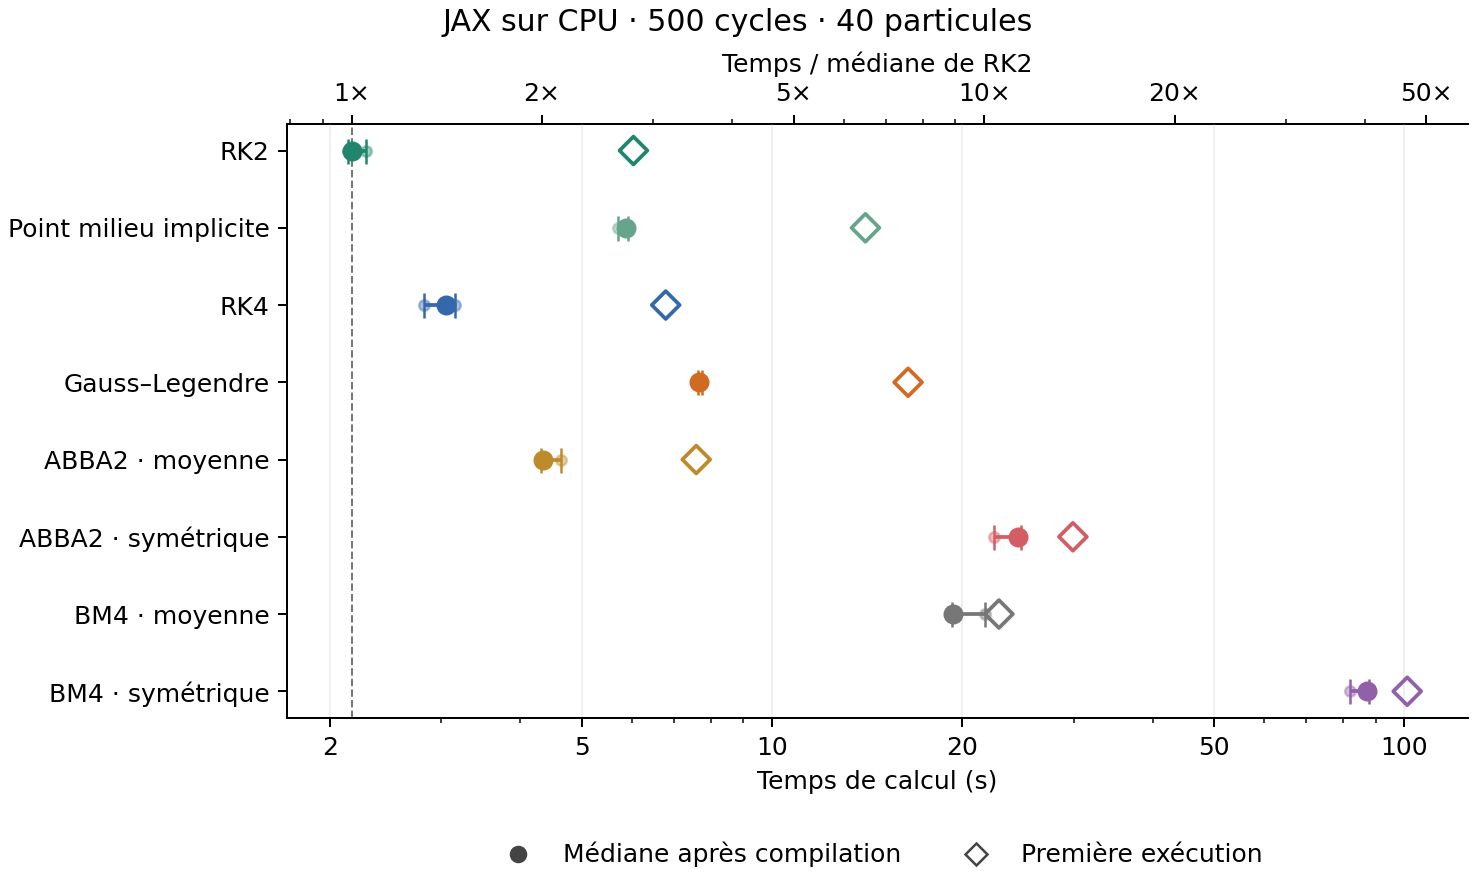

In [3]:
def plot_timings(summary):
	"""Reproduce the French thesis chart from saved measurements only."""
	rows = summary["rows"]
	if [row["method"] for row in rows] != list(METHODS):
		raise ValueError("The figure requires all eight methods in the agreed order.")
	for row in rows:
		if (not np.isfinite([row["first_seconds"], *row["warm_seconds"]]).all()
				or not 0 < row["minimum_seconds"] <= row["median_seconds"] <= row["maximum_seconds"]):
			raise ValueError("Expected positive, finite, ordered times.")
	y = np.arange(len(rows))
	median = np.array([row["median_seconds"] for row in rows])
	low = np.array([row["minimum_seconds"] for row in rows])
	high = np.array([row["maximum_seconds"] for row in rows])
	fig, ax = plt.subplots(figsize=(8.2, 4.9), layout="constrained")
	factor = float(median.min())
	baseline = LABELS[list(METHODS).index(summary["fastest_method"])]
	for i, (row, color) in enumerate(zip(rows, COLORS)):
		ax.scatter(row["warm_seconds"], [i] * len(row["warm_seconds"]), color=color, alpha=.4, s=18)
		ax.errorbar(median[i], i,
			xerr=[[float(median[i] - low[i])], [float(high[i] - median[i])]],
			fmt="o", color=color, capsize=5, markersize=7)
		ax.scatter(row["first_seconds"], i, marker="D", facecolors="none",
			edgecolors=color, s=62, linewidths=1.5)
	ax.set_yticks(y, LABELS)
	ax.invert_yaxis()
	ax.grid(True, axis="x", alpha=.2)
	ax.set_axisbelow(True)
	ax.spines[["top", "right"]].set_visible(False)
	fig.suptitle(f"JAX sur CPU · {summary['study']['cycles']} cycles · {summary['study']['particle_count']} particules", fontsize=12)
	ax.set(xscale="log", xlabel="Temps de calcul (s)")
	ax.set_xlim(float(low.min()) * .8, max(row["first_seconds"] for row in rows) * 1.25)
	ax.set_xticks([2, 5, 10, 20, 50, 100], ["2", "5", "10", "20", "50", "100"])
	ax.xaxis.set_minor_formatter(NullFormatter())
	# Both axes share one cached-median denominator, including interval endpoints.
	relative_axis = ax.secondary_xaxis("top",
		functions=(lambda seconds: seconds / factor, lambda ratio: ratio * factor))
	relative_axis.set_xlabel(f"Temps / médiane de {baseline}")
	relative_axis.set_xticks([1, 2, 5, 10, 20, 50], ["1×", "2×", "5×", "10×", "20×", "50×"])
	relative_axis.xaxis.set_minor_formatter(NullFormatter())
	ax.axvline(factor, color="#777777", lw=.8, linestyle="--", zorder=0)
	ax.legend(handles=[
		Line2D([], [], marker="o", color="#444444", linestyle="none", label="Médiane après compilation"),
		Line2D([], [], marker="D", color="#444444", markerfacecolor="none", linestyle="none", label="Première exécution"),
	], loc="upper center", bbox_to_anchor=(.5, -.17), ncol=2, frameon=False, fontsize=10)
	return fig


figure = plot_timings(summary)
plt.show()


## Optional export

Leave `EXPORT_DIRECTORY = None` to view the figure only. To save the PDF,
PNG and JSON provenance in the current runtime, set it to `Path("figures")`
and run the next cell. In Colab, download those files from the Files panel
before the runtime is deleted. The canonical scientific archives remain in
the original B2 results bucket; the public dataset is a small publication
copy containing only the timing and study JSON files plus its manifest.


In [4]:
EXPORT_DIRECTORY = None
if EXPORT_DIRECTORY is not None:
	destination = Path(EXPORT_DIRECTORY)
	destination.mkdir(parents=True, exist_ok=True)
	stem = "comparacion_tiempos_metodos_fr"
	figure_hashes = {}
	for suffix in (".pdf", ".png"):
		path = destination / (stem + suffix)
		figure.savefig(path, dpi=180,
			metadata={"Creator": "GC2D method timing study"} if suffix == ".pdf" else None)
		figure_hashes[suffix] = sha256(path.read_bytes()).hexdigest()
	provenance = dict(summary, public_data_base_url=PUBLIC_DATA_BASE_URL,
		public_manifest_sha256=EXPECTED_MANIFEST_SHA256, figure_sha256=figure_hashes,
		layout="One plot: seconds below, time divided by fastest cached median above; both axes logarithmic",
		interval="Minimum to maximum of three cached repetitions; not a confidence interval",
		relative_denominator="Fastest cached median, held fixed for all measurements and interval endpoints",
		relative_denominator_seconds=min(row["median_seconds"] for row in summary["rows"]))
	(destination / (stem + ".json")).write_text(
		json.dumps(provenance, indent=2, allow_nan=False) + "\n", encoding="utf-8")
	print("Figure and provenance saved in:", destination.resolve())
